# Baltimore 311 Resolution Time: Relationships and Linear Regression (Part 2)

**Team Chingu:** Manikrishneshwar Sasidhar, Yeo Eun Yoon

The cleaning notebook produced `log_resolution_days` = log(1 + days from `CreatedDate` to `CloseDate`). This notebook does three things:

1. Look at the actual relationship between each predictor and log resolution time, and judge whether a straight line is a fair summary.
2. Fit the linear regression those plots support, trained on 2024 and tested on 2025.
3. Check the usual linear-regression assumptions on the errors: linearity, constant variance, normality, independence, and collinearity.

A polynomial in the city deadline is a natural follow-up. It waits until the partial-residual plot says a curve would change the story.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SLA_MAX = 120
MIN_TYPE_N = 200
RNG = np.random.default_rng(311)

DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def r2_score(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    ss_res = np.sum((y - pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return 1 - ss_res / ss_tot


def regression_metrics(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    err = y - pred
    return {
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": r2_score(y, pred),
    }

## 1. Load the cleaned data

Source: `data/processed/311_clean_2024_2025.parquet` from the cleaning notebook.

`sla_days` is the city's own deadline, `DueDate - CreatedDate`, in days. It is known when the request is filed. A handful of deadlines are negative (clock or entry errors) or run past 120 days, up to about 630. Those extreme deadlines would pull a straight-line fit, so the plots and the regression use deadlines from 0 through 120 days.

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "311_clean_2024_2025.parquet")
n_raw = len(df)
n_null = int(df["sla_days"].isna().sum())
n_neg = int((df["sla_days"] < 0).sum())
n_long = int((df["sla_days"] > SLA_MAX).sum())

df = df[df["sla_days"].between(0, SLA_MAX)].copy()
df["SRType"] = df["SRType"].astype(str)
df["Agency"] = df["Agency"].astype(str)
df["MethodReceived"] = df["MethodReceived"].astype(str)

print(f"Cleaned file                         {n_raw:>10,} rows")
print(f"Missing deadline                      {n_null:>10,} rows")
print(f"Negative deadline                     {n_neg:>10,} rows")
print(f"Deadline over {SLA_MAX} days                 {n_long:>10,} rows")
print(f"Used here                            {len(df):>10,} rows")
print(f"2024 {(df.source_year == 2024).sum():,}    2025 {(df.source_year == 2025).sum():,}")
df[["resolution_days", "log_resolution_days", "sla_days"]].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
)

Cleaned file                            931,339 rows
Missing deadline                               7 rows
Negative deadline                            630 rows
Deadline over 120 days                      7,180 rows
Used here                               923,522 rows
2024 489,223    2025 434,299


,resolution_days,log_resolution_days,sla_days
count,"923,522.0000","923,522.0000","923,522.0000"
mean,14.6474,1.6355,15.5178
std,34.6295,1.3827,18.2582
min,0.0000,0.0000,0.0833
5%,0.0203,0.0201,1.0000
25%,0.5592,0.4442,2.0000
50%,2.9966,1.3854,9.0000
75%,12.2332,2.5827,20.0000
95%,62.7001,4.1542,48.3275
max,364.9814,5.9026,119.9728


## 2. What a linear relationship would look like

The predictors fall into three kinds, and "linear" means something different for each.

- **`sla_days` is a real quantity.** A linear relationship means the average log resolution time rises by the same amount for each extra day of deadline.
- **Hour, weekday, and month are stored as numbers, and they run on a cycle.** The useful check is the average at each hour, each weekday, and each month. A single slope would treat hour 23 as twenty-three times hour 1.
- **Request type, agency, and intake method are categories.** A linear model gives each category its own shift. The check is how far apart the group averages are, and whether two category columns are telling the same story.

Throughout, the modeled target is `log_resolution_days`. Raw days pile up near zero and stretch out for months, so a straight line on the day scale is pulled by the long tail. The second panel of the deadline plot keeps median days visible so the same pattern can be read in days.

## 3. Marginal relationships

These plots ignore every other predictor. They answer "what does this variable look like on its own?" The within-type plot in the next section is the one the regression actually uses.

### 3.1 City deadline

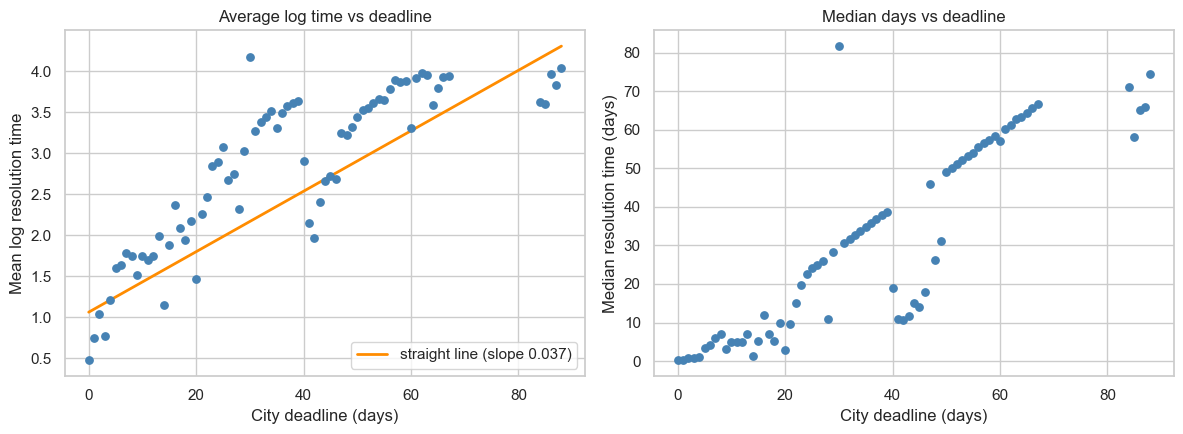

Marginal slope on the log scale: 0.0369 log-units per deadline day
Largest median-day departures from a rising pattern (bins with n >= 500):


,n,mean_log,median_days
sla_days,,,
30,7259,4.1725,81.6675
88,646,4.0402,74.3817
84,5331,3.6272,71.0429
67,610,3.9428,66.6369
87,708,3.8323,65.9554


In [3]:
sla_bin = df["sla_days"].round().astype(int)
binned = (
    df.groupby(sla_bin)
    .agg(
        n=("log_resolution_days", "size"),
        mean_log=("log_resolution_days", "mean"),
        median_days=("resolution_days", "median"),
    )
)
binned = binned[binned["n"] >= 500]
slope, intercept = np.polyfit(df["sla_days"], df["log_resolution_days"], 1)
x_line = np.linspace(binned.index.min(), binned.index.max(), 200)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(binned.index, binned["mean_log"], s=28, color="steelblue", zorder=3)
axes[0].plot(x_line, intercept + slope * x_line, color="darkorange", linewidth=2,
             label=f"straight line (slope {slope:.3f})")
axes[0].set_xlabel("City deadline (days)")
axes[0].set_ylabel("Mean log resolution time")
axes[0].set_title("Average log time vs deadline")
axes[0].legend()

axes[1].scatter(binned.index, binned["median_days"], s=28, color="steelblue")
axes[1].set_xlabel("City deadline (days)")
axes[1].set_ylabel("Median resolution time (days)")
axes[1].set_title("Median days vs deadline")
savefig("08_sla_marginal")

print(f"Marginal slope on the log scale: {slope:.4f} log-units per deadline day")
print("Largest median-day departures from a rising pattern (bins with n >= 500):")
show = binned.sort_values("median_days", ascending=False).head(5)
show.index.name = "sla_days"
show

The average log time rises with the deadline, and a straight line is only a rough summary of that rise. Individual deadlines sit well off the line. The common 42-day deadline (bulk collection) closes much faster than the 30-day deadline, which is the slowest large bin in median days. Those jumps are different kinds of work assigned different deadlines, not a smooth curve in the deadline itself.

Read the marginal slope with that in mind. It mixes two things: slow request types tend to be given long deadlines, and, within a type, a longer deadline may go with a longer close. The next section separates them.

### 3.2 Hour, weekday, and month

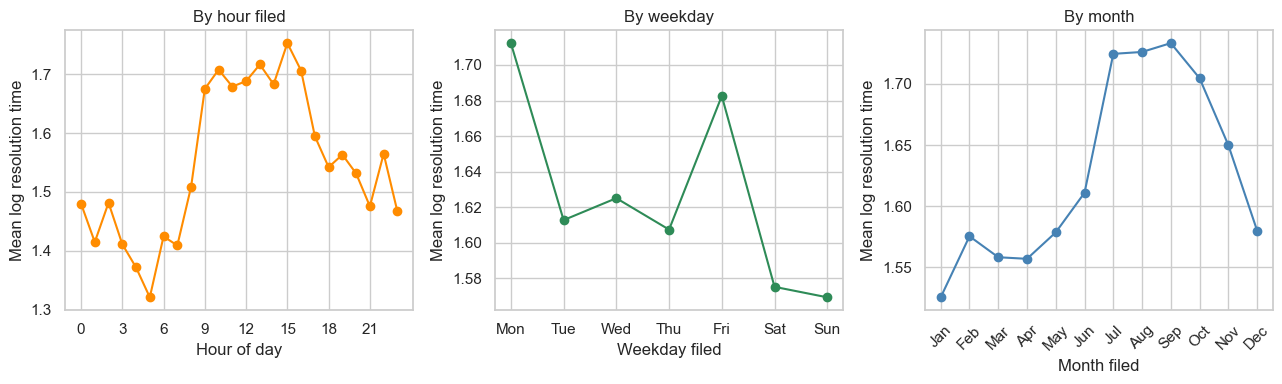

Hour range in mean log time:    0.432
Weekday range in mean log time: 0.143
Month range in mean log time:   0.208


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

by_hour = df.groupby("created_hour")["log_resolution_days"].mean()
axes[0].plot(by_hour.index, by_hour.values, marker="o", color="darkorange")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Mean log resolution time")
axes[0].set_title("By hour filed")
axes[0].set_xticks(range(0, 24, 3))

by_dow = df.groupby("created_dayofweek")["log_resolution_days"].mean()
axes[1].plot(by_dow.index, by_dow.values, marker="o", color="seagreen")
axes[1].set_xticks(range(7), DOW_NAMES)
axes[1].set_xlabel("Weekday filed")
axes[1].set_ylabel("Mean log resolution time")
axes[1].set_title("By weekday")

by_month = df.groupby("created_month")["log_resolution_days"].mean()
axes[2].plot(by_month.index, by_month.values, marker="o", color="steelblue")
axes[2].set_xticks(range(1, 13), MONTH_NAMES, rotation=45)
axes[2].set_xlabel("Month filed")
axes[2].set_ylabel("Mean log resolution time")
axes[2].set_title("By month")
savefig("09_calendar_means")

print(f"Hour range in mean log time:    {by_hour.max() - by_hour.min():.3f}")
print(f"Weekday range in mean log time: {by_dow.max() - by_dow.min():.3f}")
print(f"Month range in mean log time:   {by_month.max() - by_month.min():.3f}")

None of the three is a straight line in its numeric code. Hour drops in the early morning, jumps at the start of the workday, and falls off in the evening. Weekday is a small dip from Monday to the weekend, with Friday close to Monday. Month rises from winter into a late-summer plateau and comes back down.

The vertical range is a few tenths of a log unit. Request types, below, differ by much more than that. Hour, weekday, and month enter the regression as separate category shifts, which matches these shapes. They do not enter as single slopes.

### 3.3 Categories, and how much each predictor accounts for

Share of variation in log resolution time associated with each predictor on its own


,predictor,share_of_log_variance
0,Request type,0.4623
1,Agency,0.0946
2,Neighborhood,0.0155
3,Hour filed,0.0052
4,Council district,0.0037
5,Month filed,0.0030
6,Intake method,0.0013
7,Weekday filed,0.0011
8,Latitude,0.0006
9,Longitude,0.0000


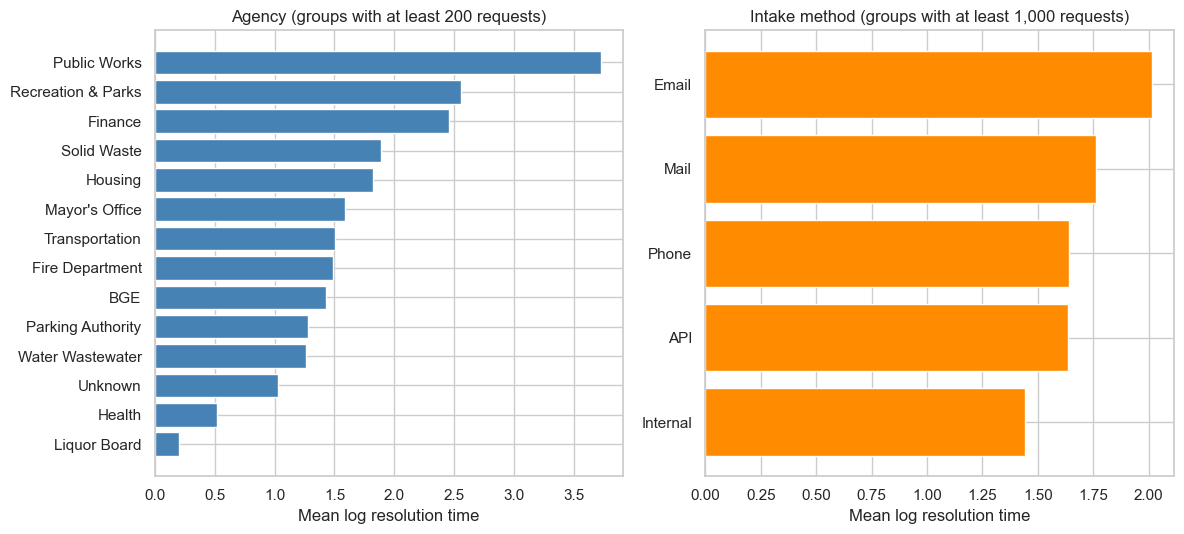

Request types that appear under more than one agency: 17 of 269


In [5]:
def eta_squared(frame, column):
    y = frame["log_resolution_days"]
    means = frame.groupby(column, observed=True)["log_resolution_days"].transform("mean")
    ss_tot = ((y - y.mean()) ** 2).sum()
    ss_res = ((y - means) ** 2).sum()
    return 1 - ss_res / ss_tot


association = pd.DataFrame({
    "predictor": [
        "Request type", "Agency", "Neighborhood", "Hour filed",
        "Council district", "Month filed", "Weekday filed", "Intake method",
        "Latitude", "Longitude",
    ],
    "share_of_log_variance": [
        eta_squared(df, "SRType"),
        eta_squared(df, "Agency"),
        eta_squared(df, "Neighborhood"),
        eta_squared(df, "created_hour"),
        eta_squared(df, "CouncilDistrict"),
        eta_squared(df, "created_month"),
        eta_squared(df, "created_dayofweek"),
        eta_squared(df, "MethodReceived"),
        np.nan,
        np.nan,
    ],
})
association.loc[association["predictor"] == "Latitude", "share_of_log_variance"] = (
    df["Latitude"].corr(df["log_resolution_days"]) ** 2
)
association.loc[association["predictor"] == "Longitude", "share_of_log_variance"] = (
    df["Longitude"].corr(df["log_resolution_days"]) ** 2
)
association = association.sort_values("share_of_log_variance", ascending=False)
association["share_of_log_variance"] = association["share_of_log_variance"].round(4)
print("Share of variation in log resolution time associated with each predictor on its own")
display(association.reset_index(drop=True))

agency = (
    df.groupby("Agency")["log_resolution_days"]
    .agg(n="size", mean_log="mean")
    .query("n >= 200")
    .sort_values("mean_log")
)
method = (
    df.groupby("MethodReceived")["log_resolution_days"]
    .agg(n="size", mean_log="mean")
    .query("n >= 1000")
    .sort_values("mean_log")
)
types_multi_agency = int((df.groupby("SRType")["Agency"].nunique() > 1).sum())
n_types = df["SRType"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
axes[0].barh(agency.index, agency["mean_log"], color="steelblue")
axes[0].set_xlabel("Mean log resolution time")
axes[0].set_title("Agency (groups with at least 200 requests)")
axes[1].barh(method.index, method["mean_log"], color="darkorange")
axes[1].set_xlabel("Mean log resolution time")
axes[1].set_title("Intake method (groups with at least 1,000 requests)")
savefig("10_group_means")
print(f"Request types that appear under more than one agency: {types_multi_agency} of {n_types}")

Request type is the relationship. On its own it accounts for just under half the variation in log resolution time. Agency looks important in the bar chart, and almost every request type belongs to a single agency, so the agency gaps are mostly type gaps under another name. Putting both in the regression would split one effect across two collinear blocks. Agency stays out.

Intake method barely moves the average. Phone and the API, which are the bulk of the file, sit together. Email is slower, on a much smaller volume. Neighborhood, council district, latitude, and longitude account for little of the log-time variation in a straight additive sense, so they stay out of this regression.

Hour, month, and weekday each account for well under one percent on their own. They stay in the model as category shifts because their plots have a shape, and the coefficient chart later shows how small that shape is once request type is held fixed.

## 4. Within request type, is the deadline linear?

Once each request is compared with its own type, the deadline is no longer standing in for "this is a slow kind of work." Both axes below are differences from the request type's own average. A point to the right is a case given a longer deadline than that type usually gets. A point above zero took longer to close than that type usually takes.

The orange line is the best straight line through those within-type differences. Point area grows with the number of requests in the bin.

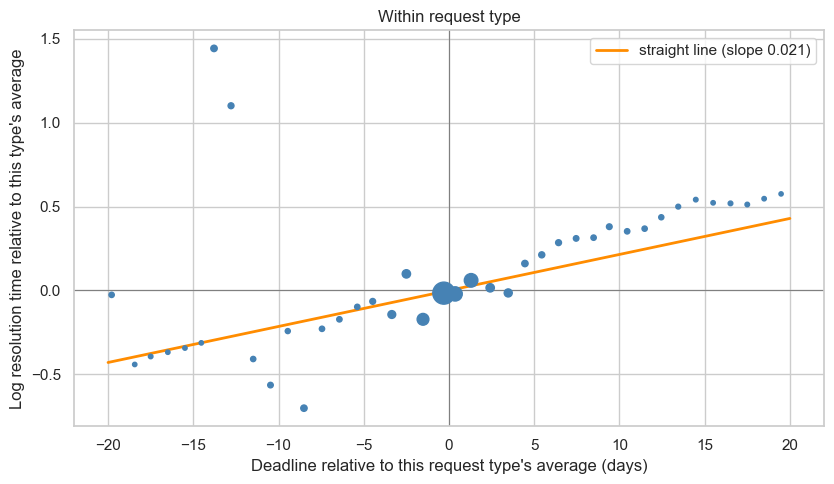

Within-type correlation: 0.109
Within-type slope:       0.0215 log-units per extra deadline day
Share of these requests within 1 day of the type's usual deadline: 73.0%

Requests 12 to 14 days under the usual deadline: 7,035
SRType
SW-City Trash Can or Recycling Cart Concern           3310
SW-City Trash Can or Recycling Cart Lost or Stolen    1882
SW-Bulk Scheduled-Weekday                             1337
SW-Bulk Scheduled-Saturday                             420


In [6]:
type_n = df.groupby("SRType")["sla_days"].transform("size")
within = df[type_n >= MIN_TYPE_N].copy()
within["sla_dm"] = within["sla_days"] - within.groupby("SRType")["sla_days"].transform("mean")
within["y_dm"] = (
    within["log_resolution_days"]
    - within.groupby("SRType")["log_resolution_days"].transform("mean")
)
within_slope, within_intercept = np.polyfit(within["sla_dm"], within["y_dm"], 1)
near = within["sla_dm"].abs().le(1).mean()

within["sla_bin"] = pd.cut(within["sla_dm"], bins=np.linspace(-20, 20, 41))
wb = (
    within.groupby("sla_bin", observed=True)
    .agg(n=("y_dm", "size"), mean_x=("sla_dm", "mean"), mean_y=("y_dm", "mean"))
)
wb = wb[wb["n"] >= 300]

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.scatter(wb["mean_x"], wb["mean_y"], s=np.sqrt(wb["n"]) / 3, color="steelblue", zorder=3)
x_line = np.linspace(-20, 20, 100)
ax.plot(x_line, within_intercept + within_slope * x_line, color="darkorange", linewidth=2,
        label=f"straight line (slope {within_slope:.3f})")
ax.set_xlabel("Deadline relative to this request type's average (days)")
ax.set_ylabel("Log resolution time relative to this type's average")
ax.set_title("Within request type")
ax.legend()
savefig("11_within_type_sla")

print(f"Within-type correlation: {within['sla_dm'].corr(within['y_dm']):.3f}")
print(f"Within-type slope:       {within_slope:.4f} log-units per extra deadline day")
print(f"Share of these requests within 1 day of the type's usual deadline: {near:.1%}")

pocket = within[within["sla_dm"].between(-14, -12)]
print(f"\nRequests 12 to 14 days under the usual deadline: {len(pocket):,}")
print(pocket["SRType"].value_counts().head(4).to_string())

The within-type slope is positive and shallow, and the correlation is weak. Most requests (73%) sit within a day of the deadline their type usually receives, because the deadline is largely a label for the type. Through the dense middle of the plot the bin means follow the straight line.

Two departures are visible. Past about five days over the usual deadline, the bin means sit above the line, so one slope is a little flat on that side. And requests filed about two weeks under the usual deadline close slowly. That band is mostly city trash-cart complaints (concerns, and lost or stolen carts), plus some bulk-scheduled pickups. It is a pocket of a few request types. A squared term could bend the right-hand side; it would not represent that pocket. The polynomial comparison can wait until the regression's own partial-residual plot is in hand.

## 5. The model those plots support

Training requests are 2024. Test requests are 2025, scored once, after the fit.

$$
\log(1 + \text{days}) = \beta_0 + \beta_{\text{sla}} \cdot \text{sla\_days} + \text{request type} + \text{month} + \text{weekday} + \text{hour} + \varepsilon
$$

- **`sla_days`** has one slope. Within type, the binned means rise approximately in a straight line.
- **Request type** enters as an indicator per type. Types with fewer than 200 training requests share one "Other" indicator, as do any 2025 types that never reached that count in 2024.
- **Month, weekday, and hour** enter as indicators. Their averages are not straight lines in the numeric codes, and the shifts are small.
- **Agency** stays out, because type already carries it.
- **Intake method, neighborhood, council district, and coordinates** stay out. Their marginal association with log time is small beside request type.

The reference row is the most common request type, January, Monday, and the most common filing hour. Every coefficient is a difference from that baseline. The baseline's own coefficients are zero.

In [7]:
train = df[df["source_year"] == 2024].copy()
test = df[df["source_year"] == 2025].copy()

type_counts = train["SRType"].value_counts()
common_types = set(type_counts[type_counts >= MIN_TYPE_N].index)
train["request_type"] = np.where(train["SRType"].isin(common_types), train["SRType"], "Other")
test["request_type"] = np.where(test["SRType"].isin(common_types), test["SRType"], "Other")

ref_type = train["request_type"].value_counts().idxmax()
ref_hour = int(train["created_hour"].mode().iloc[0])

print(f"Training rows: {len(train):,}")
print(f"Test rows:     {len(test):,}")
print(f"Request types with their own coefficient: {len(common_types):,}")
print(f"Share of training rows in Other: {(train['request_type'] == 'Other').mean():.1%}")
print(f"Share of test rows in Other:     {(test['request_type'] == 'Other').mean():.1%}")
print(f"Reference type: {ref_type}")
print(f"Reference hour: {ref_hour}:00")


def design_matrix(frame, columns=None, drop_cols=None):
    pieces = frame[["sla_days", "request_type", "created_month", "created_dayofweek", "created_hour"]].copy()
    pieces["created_month"] = pieces["created_month"].astype(int)
    pieces["created_dayofweek"] = pieces["created_dayofweek"].astype(int)
    pieces["created_hour"] = pieces["created_hour"].astype(int)
    X = pd.get_dummies(
        pieces,
        columns=["request_type", "created_month", "created_dayofweek", "created_hour"],
        dtype=float,
    )
    if columns is None:
        missing = [c for c in drop_cols if c not in X.columns]
        if missing:
            raise KeyError(f"Reference columns missing from the design matrix: {missing}")
        X = X.drop(columns=drop_cols)
        return sm.add_constant(X, has_constant="add")
    X = sm.add_constant(X, has_constant="add")
    return X.reindex(columns=columns, fill_value=0.0)


drop_cols = [
    f"request_type_{ref_type}",
    "created_month_1",
    "created_dayofweek_0",
    f"created_hour_{ref_hour}",
]
X_train = design_matrix(train, drop_cols=drop_cols)
X_test = design_matrix(test, columns=list(X_train.columns))
y_train = train["log_resolution_days"].to_numpy()
y_test = test["log_resolution_days"].to_numpy()

model = sm.OLS(y_train, X_train.to_numpy()).fit()
print(f"Fitted coefficients (including the intercept): {int(model.df_model) + 1}")
print(f"Training R² on the log scale: {model.rsquared:.4f}")

Training rows: 489,223
Test rows:     434,299
Request types with their own coefficient: 138
Share of training rows in Other: 1.4%
Share of test rows in Other:     1.9%
Reference type: HCD-Sanitation Property
Reference hour: 10:00


Fitted coefficients (including the intercept): 180
Training R² on the log scale: 0.5441


## 6. Test performance

Day-scale predictions are `expm1` of the fitted log value: predict log(1 + days), then convert back to days. If the log errors were symmetric, that conversion would track the median resolution time. The comparison that matters is against two simple rules fit on 2024 only: one median for every request, and the median of each request type.

In [8]:
pred_train = model.predict(X_train.to_numpy())
pred_test = model.predict(X_test.to_numpy())
pred_test_days = np.expm1(pred_test)

type_median = train.groupby("request_type")["resolution_days"].median()
type_mean_log = train.groupby("request_type")["log_resolution_days"].mean()
pred_type_median = test["request_type"].map(type_median).to_numpy()
pred_type_log = test["request_type"].map(type_mean_log).to_numpy()
pred_global = np.full(len(test), train["resolution_days"].median())

day_rows = pd.DataFrame([
    {"model": "One median for every request", **regression_metrics(test["resolution_days"], pred_global)},
    {"model": "Median of each request type", **regression_metrics(test["resolution_days"], pred_type_median)},
    {"model": "Linear regression", **regression_metrics(test["resolution_days"], pred_test_days)},
])
log_rows = pd.DataFrame([
    {"model": "Mean log time of each request type", "R2_log": r2_score(y_test, pred_type_log)},
    {"model": "Linear regression", "R2_log": r2_score(y_test, pred_test)},
])

train_type_mean = train.groupby("request_type")["log_resolution_days"].transform("mean")
print(f"Training R², request-type averages only: {r2_score(y_train, train_type_mean):.4f}")
print(f"Training R², full linear model:          {model.rsquared:.4f}")
print()
print("2025 test set, scored in days")
display(day_rows.round(3))
print("2025 test set, scored on the log scale")
display(log_rows.round(3))

Training R², request-type averages only: 0.5254
Training R², full linear model:          0.5441

2025 test set, scored in days


,model,MAE,RMSE,R2
0,One median for every request,14.7120,38.8830,-0.1150
1,Median of each request type,11.9150,35.9590,0.0470
2,Linear regression,11.5900,35.8720,0.0510


2025 test set, scored on the log scale


,model,R2_log
0,Mean log time of each request type,0.3010
1,Linear regression,0.3150


Almost all of the fit is the request-type indicators. On 2024 data the full model is only a little above type averages, and on 2025 the deadline slope plus the calendar indicators add about a hundredth to log-scale R².

In days, the linear model beats "guess the overall median" and lands very close to "guess this request type's median." R² in days stays near zero because squared error is dominated by the long tail: a small share of requests takes months, and RMSE weights those heavily. MAE is the number that describes a typical request. The errors there are still on the order of ten days.

The drop from the training log R² to the 2025 log R² is mostly request types resolving at a different pace in 2025 than in 2024. The assumption checks below come back to that.

## 7. What the coefficients say

The deadline coefficient is a within-type slope: request type is held fixed. Calendar coefficients are differences from January, Monday, and the reference hour, also with request type held fixed. Type coefficients are differences from the reference type and run much wider than the calendar shifts. The histogram is the useful view of those; a table of 100-plus type coefficients is not.

Deadline slope: 0.0287 log-units per day
  classical SE 0.00024    95% CI [0.0283, 0.0292]
  HC0 SE       0.00026    95% CI [0.0282, 0.0293]
  percent change in (1 + days) per extra deadline day: 2.92%
Within-type descriptive slope from section 4 was 0.0215


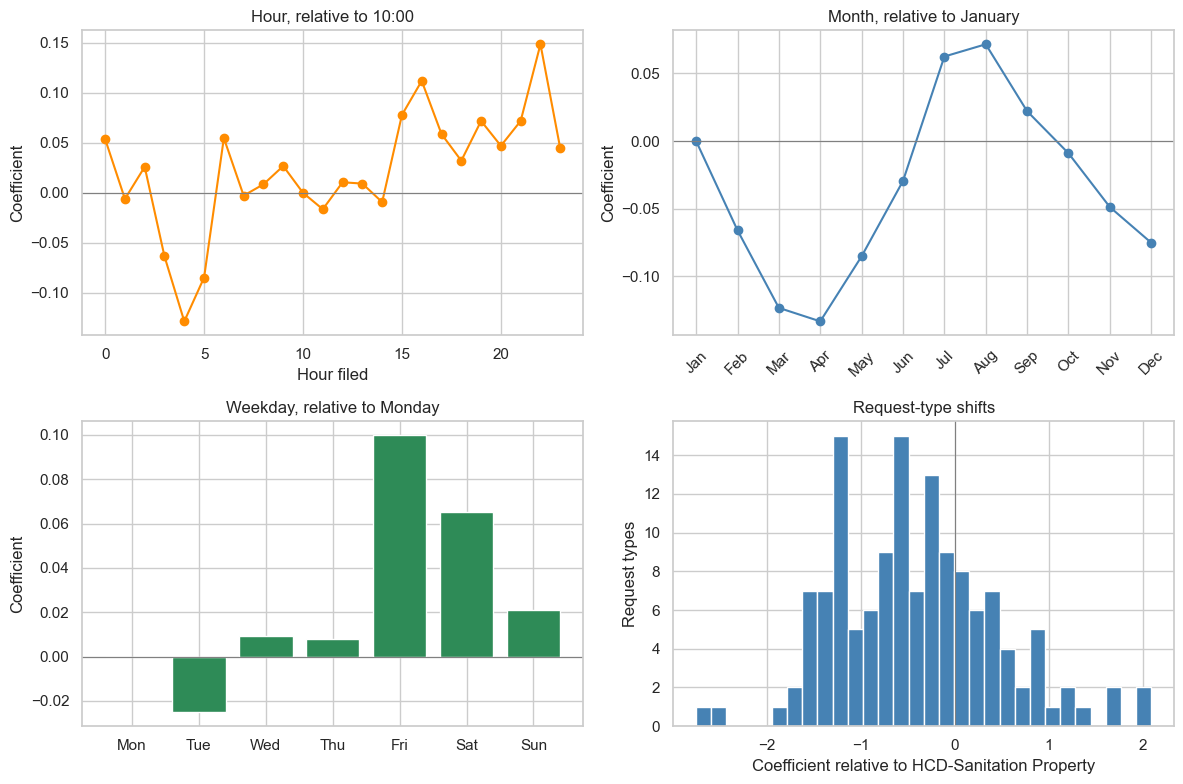

Calendar coefficients span -0.133 to 0.149
Request-type coefficients span -2.750 to 2.088

Slowest types relative to the reference
request_type_TRT-Flex posts               2.0880
request_type_TRM-Footways Repair          1.9560
request_type_RP-Street Lighting Repairs   1.6800
request_type_TRT-Signal Timing            1.6490
request_type_FOR-Broken Branch in Tree    1.3580
request_type_RP-Building Maintenance      1.1690
request_type_HCD-Zoning Investigation     1.1560
request_type_FOR-Fallen Limb              1.0090

Fastest types relative to the reference
request_type_ECC-MPIA Request                                                    -2.7500
request_type_TRA-Red Light/Speed/Truck Camera                                    -2.5840
request_type_PABC-Residential Reserved Disabled Parking Request                  -1.8020
request_type_HLTH-Animal Wildlife Complaint                                      -1.6940
request_type_HLTH-Animal Failure to Restrain Animal, Known Owner/Known Address  

In [9]:
names = list(X_train.columns)
params = pd.Series(model.params, index=names)
bse = pd.Series(model.bse, index=names)
sla_coef = float(params["sla_days"])
sla_se = float(bse["sla_days"])

# HC0 standard error for the deadline slope. Classical SEs assume constant variance,
# and the next section shows the variance is not constant.
x = X_train.to_numpy()
resid = y_train - pred_train
xtx_inv = model.normalized_cov_params
meat = (x * resid[:, None]).T @ (x * resid[:, None])
hc0 = xtx_inv @ meat @ xtx_inv
sla_idx = names.index("sla_days")
sla_se_hc0 = float(np.sqrt(hc0[sla_idx, sla_idx]))

print(f"Deadline slope: {sla_coef:.4f} log-units per day")
print(f"  classical SE {sla_se:.5f}    95% CI [{sla_coef - 1.96 * sla_se:.4f}, {sla_coef + 1.96 * sla_se:.4f}]")
print(f"  HC0 SE       {sla_se_hc0:.5f}    95% CI [{sla_coef - 1.96 * sla_se_hc0:.4f}, {sla_coef + 1.96 * sla_se_hc0:.4f}]")
print(f"  percent change in (1 + days) per extra deadline day: {(np.exp(sla_coef) - 1) * 100:.2f}%")
print(f"Within-type descriptive slope from section 4 was {within_slope:.4f}")

month_coef = pd.Series(0.0, index=range(1, 13), name="coef")
for month in range(2, 13):
    month_coef.loc[month] = params[f"created_month_{month}"]
dow_coef = pd.Series(0.0, index=range(7), name="coef")
for dow in range(1, 7):
    dow_coef.loc[dow] = params[f"created_dayofweek_{dow}"]
hour_coef = pd.Series(0.0, index=range(24), name="coef")
for hour in range(24):
    col = f"created_hour_{hour}"
    if col in params.index:
        hour_coef.loc[hour] = params[col]

type_coef = params[params.index.str.startswith("request_type_")].sort_values()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(hour_coef.index, hour_coef.values, marker="o", color="darkorange")
axes[0, 0].axhline(0, color="gray", linewidth=0.8)
axes[0, 0].set_xlabel("Hour filed")
axes[0, 0].set_ylabel("Coefficient")
axes[0, 0].set_title(f"Hour, relative to {ref_hour}:00")

axes[0, 1].plot(month_coef.index, month_coef.values, marker="o", color="steelblue")
axes[0, 1].axhline(0, color="gray", linewidth=0.8)
axes[0, 1].set_xticks(range(1, 13), MONTH_NAMES, rotation=45)
axes[0, 1].set_ylabel("Coefficient")
axes[0, 1].set_title("Month, relative to January")

axes[1, 0].bar(dow_coef.index, dow_coef.values, color="seagreen")
axes[1, 0].axhline(0, color="gray", linewidth=0.8)
axes[1, 0].set_xticks(range(7), DOW_NAMES)
axes[1, 0].set_ylabel("Coefficient")
axes[1, 0].set_title("Weekday, relative to Monday")

axes[1, 1].hist(type_coef, bins=30, color="steelblue", edgecolor="white")
axes[1, 1].axvline(0, color="gray", linewidth=0.8)
axes[1, 1].set_xlabel(f"Coefficient relative to {ref_type}")
axes[1, 1].set_ylabel("Request types")
axes[1, 1].set_title("Request-type shifts")
savefig("12_coefficient_sizes")

print(f"Calendar coefficients span {min(hour_coef.min(), month_coef.min(), dow_coef.min()):.3f} to {max(hour_coef.max(), month_coef.max(), dow_coef.max()):.3f}")
print(f"Request-type coefficients span {type_coef.min():.3f} to {type_coef.max():.3f}")
print("\nSlowest types relative to the reference")
print(type_coef.tail(8).sort_values(ascending=False).round(3).to_string())
print("\nFastest types relative to the reference")
print(type_coef.head(8).round(3).to_string())

With type indicators in the model, the deadline slope is a within-type slope. The fitted value is about 0.029 log units per day, a bit steeper than the 0.022 line drawn through both years in section 4. Either way, an extra deadline day goes with about a 3% increase in (1 + resolution days). That association is precise at this sample size, and it is small next to request type.

The calendar coefficients are those shapes with request type held fixed. Early morning is faster than 10:00, and the evening is slower. Spring is faster than January, and late summer is a little slower. Friday is the slow weekday. The shapes are still curved, which is why these enter as indicators. They stay inside about ±0.15 log units. Type coefficients run from about −2.8 to +2.1, a multiplicative gap of several times in (1 + days). The robust standard error for the deadline slope is in the assumption checks below.

## 8. Assumption checks

Five assumptions sit under this regression. With about half a million training rows, a formal test will flag tiny departures, so each check is a plot first and a test second.

1. **Linearity.** The average of the target moves in a straight line with `sla_days`, once the categories are held fixed.
2. **Constant variance.** The spread of the errors does not depend on the fitted value.
3. **Normal errors.** The errors follow a normal curve. At this sample size the coefficients stay well estimated under moderate departures; normality is what prediction intervals lean on.
4. **Independent errors.** One request's miss does not say anything about another's. In particular, misses should not cluster by the week or month the request was filed.
5. **Collinearity.** The deadline is not a copy of the request-type indicators.

Training residuals are actual log time minus fitted log time. Month and hour indicators force the training residual average in each month and hour to zero, so those training averages are not evidence about independence. The 2025 residuals are.

### 8.1 Linearity

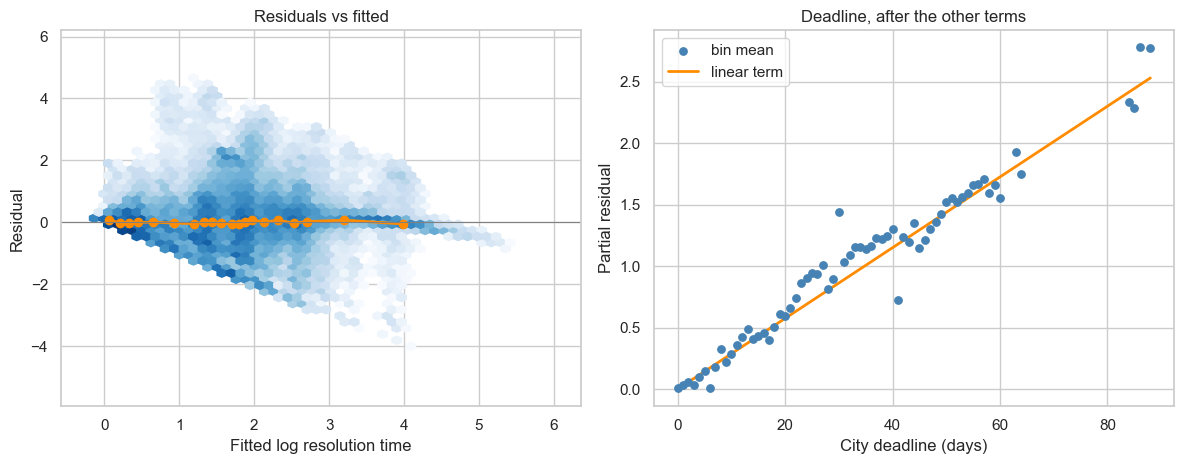

Mean residual: 4.795e-15
Largest |bin-mean residual| across 20 fitted bins: 0.078


In [10]:
sla_train = train["sla_days"].to_numpy()
partial = resid + sla_coef * sla_train

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].hexbin(pred_train, resid, gridsize=50, cmap="Blues", mincnt=20, bins="log")
fitted_bin = pd.qcut(pred_train, 20, duplicates="drop")
bin_mean = pd.DataFrame({"fitted": pred_train, "resid": resid}).groupby(fitted_bin, observed=True).mean()
axes[0].plot(bin_mean["fitted"], bin_mean["resid"], color="darkorange", marker="o", linewidth=2)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_xlabel("Fitted log resolution time")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs fitted")

partial_frame = pd.DataFrame({"sla": sla_train.round().astype(int), "partial": partial})
pb = partial_frame.groupby("sla").agg(n=("partial", "size"), mean_partial=("partial", "mean"))
pb = pb[pb["n"] >= 500]
axes[1].scatter(pb.index, pb["mean_partial"], s=28, color="steelblue", zorder=3, label="bin mean")
x_line = np.linspace(pb.index.min(), pb.index.max(), 200)
axes[1].plot(x_line, sla_coef * x_line, color="darkorange", linewidth=2, label="linear term")
axes[1].set_xlabel("City deadline (days)")
axes[1].set_ylabel("Partial residual")
axes[1].set_title("Deadline, after the other terms")
axes[1].legend()
savefig("13_residuals_linearity")

print(f"Mean residual: {resid.mean():.3e}")
print(f"Largest |bin-mean residual| across 20 fitted bins: {bin_mean['resid'].abs().max():.3f}")

The residuals have mean zero, and the orange bin means on the left sit on the horizontal line. The largest bin-mean residual is under a tenth of a log unit. The cloud has a hard floor: log resolution time cannot go below zero, so a residual cannot be more negative than minus the fitted value. That floor, and the way the cloud widens after the fastest fitted values, is the constant-variance check in the next section.

The right-hand plot is the deadline with request type and the calendar removed. The bin means track the straight line. Holding request type fixed takes away the stripes and the large jumps from the marginal plot. A few deadlines between about 20 and 40 days sit off the line. A squared term could pick those up. On this plot it is a small refinement of a relationship that is already close to linear.

### 8.2 Constant variance, and normal errors

Residual standard deviation by decile of the fitted value


,n,residual_sd
-0.26 to 0.27,48925,0.2900
0.27 to 0.52,48920,0.4090
0.52 to 1.08,48923,0.8930
1.08 to 1.38,48922,0.8900
1.38 to 1.64,48922,1.1310
1.64 to 1.84,48922,1.1340
1.84 to 2.04,48922,1.1000
2.04 to 2.44,48922,1.1010
2.44 to 2.87,48931,0.9540
2.87 to 6.05,48914,0.9020


Breusch-Pagan LM = 122,668, p = 0.000e+00
Residual skew: 0.696    excess kurtosis: 2.786
(A normal curve has skew 0 and excess kurtosis 0.)


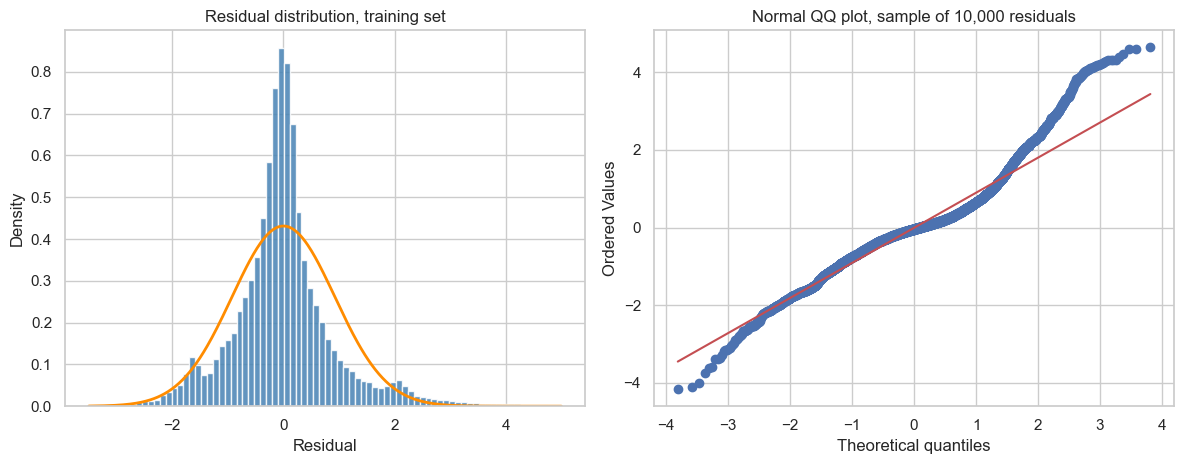

Residual SD in the tightest fitted decile: 0.290
Residual SD in the widest fitted decile:   1.134


In [11]:
decile = pd.qcut(pred_train, 10, duplicates="drop")
spread = (
    pd.DataFrame({"decile": decile, "resid": resid})
    .groupby("decile", observed=True)["resid"]
    .agg(n="size", residual_sd="std")
)
spread.index = [f"{interval.left:.2f} to {interval.right:.2f}" for interval in spread.index]
print("Residual standard deviation by decile of the fitted value")
display(spread.round(3))

lm_stat, lm_p, f_stat, f_p = het_breuschpagan(resid, X_train.to_numpy())
print(f"Breusch-Pagan LM = {lm_stat:,.0f}, p = {lm_p:.3e}")

skew = float(pd.Series(resid).skew())
excess_kurtosis = float(pd.Series(resid).kurtosis())
print(f"Residual skew: {skew:.3f}    excess kurtosis: {excess_kurtosis:.3f}")
print("(A normal curve has skew 0 and excess kurtosis 0.)")

qq_sample = RNG.choice(resid, size=10000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
xs = np.linspace(-3.5, 5, 400)
axes[0].hist(resid, bins=80, density=True, range=(-3.5, 5), color="steelblue", alpha=0.85)
axes[0].plot(xs, stats.norm.pdf(xs, loc=resid.mean(), scale=resid.std()), color="darkorange", linewidth=2)
axes[0].set_xlabel("Residual")
axes[0].set_ylabel("Density")
axes[0].set_title("Residual distribution, training set")

stats.probplot(qq_sample, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ plot, sample of 10,000 residuals")
savefig("14_residual_normality")
print(f"Residual SD in the tightest fitted decile: {spread['residual_sd'].min():.3f}")
print(f"Residual SD in the widest fitted decile:   {spread['residual_sd'].max():.3f}")

The spread is not constant. Residual SD is about 0.29 in the fastest fitted decile and about 1.13 through the middle of the range, then eases toward 0.90 for the slowest fitted values. The Breusch-Pagan test rejects equal variance; at this sample size it would reject a much smaller gap. The decile table is the useful part: the model is much more precise about requests it expects to close quickly than about the rest.

The HC0 interval in the coefficient section is the direct consequence. For the deadline slope it is only slightly wider than the classical interval (0.00026 versus 0.00024), and the estimate is unchanged. Intervals for other coefficients that use the classical standard errors are somewhat too sure of themselves, especially away from the quick-request cases.

The errors are more peaked than a normal curve. The histogram spikes at zero well above the normal curve with the same mean and SD, and the right tail is longer. Skew is 0.70 and excess kurtosis is 2.79. The QQ plot follows the reference line in a band around zero and bends upward in the right tail. A Jarque-Bera test would reject at this sample size and would not add a distinction the plot does not already show. Coefficients of this size, with this many rows, are still well estimated. A normal-based prediction interval would be too narrow in the tails: the requests that take months happen more often than a normal error would say.

### 8.3 Independence over time

2025 residuals by month filed. Training month-means are zero because month indicators absorb them.


,n,mean_log_residual,mean_actual_days,mean_predicted_days
Jan,43276,0.0290,12.2410,6.6470
Feb,36270,0.0510,14.4500,7.2860
Mar,39759,0.0680,14.5050,7.1120
Apr,3085,0.2480,36.1200,8.5030
May,11140,0.0050,17.0550,7.5530
Jun,46829,0.0310,12.4290,7.7190
Jul,49226,0.0930,13.8230,8.4720
Aug,51860,0.1090,15.3480,8.3260
Sep,44008,0.2980,18.7900,8.1290
Oct,42162,0.2710,19.1110,8.1290


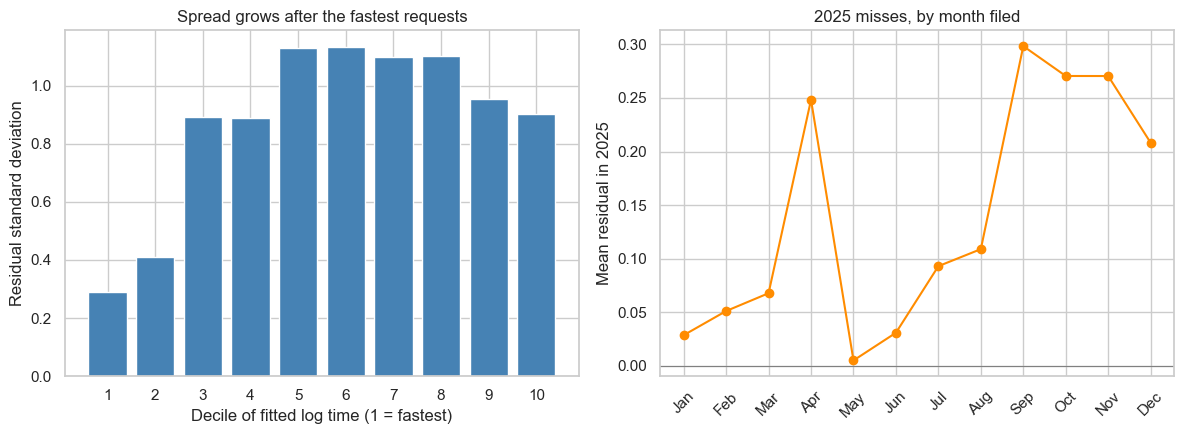

In [12]:
test_resid = y_test - pred_test
by_month = (
    pd.DataFrame({
        "month": test["created_month"].to_numpy(),
        "resid": test_resid,
        "days": test["resolution_days"].to_numpy(),
        "pred_days": pred_test_days,
    })
    .groupby("month")
    .agg(
        n=("resid", "size"),
        mean_log_residual=("resid", "mean"),
        mean_actual_days=("days", "mean"),
        mean_predicted_days=("pred_days", "mean"),
    )
)
by_month.index = MONTH_NAMES
print("2025 residuals by month filed. Training month-means are zero because month indicators absorb them.")
display(by_month.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(range(len(spread)), spread["residual_sd"].to_numpy(), color="steelblue")
axes[0].set_xticks(range(len(spread)), [str(i + 1) for i in range(len(spread))])
axes[0].set_xlabel("Decile of fitted log time (1 = fastest)")
axes[0].set_ylabel("Residual standard deviation")
axes[0].set_title("Spread grows after the fastest requests")

axes[1].plot(range(1, 13), by_month["mean_log_residual"], marker="o", color="darkorange")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_xticks(range(1, 13), MONTH_NAMES, rotation=45)
axes[1].set_ylabel("Mean residual in 2025")
axes[1].set_title("2025 misses, by month filed")
savefig("15_variance_and_time")

A positive residual means the request took longer, on the log scale, than the 2024 model predicted. April 2025 shows a large residual and only about 3,000 requests, against 30,000–50,000 in a typical month, so that point is a thin slice of the file. September through December are full months, and their mean log residual is about 0.2 to 0.3. Requests filed in the same stretch of the year share a miss.

Mean predicted days sit below mean actual days even in months where the log residual is near zero. That gap is the conversion back from the log scale: `expm1` of a log prediction tracks a typical request, and the average in days is pulled up by the long tail. The log residual is the bias check. The day columns are the long-tail check.

The rows are not independent, and the calendar part of the model is not stable across years. Classical standard errors, which treat 489,000 requests as unrelated draws, are too small. A model that fits 2024 well is systematically slow for the fall of 2025. A squared deadline term does not address that. It is a shift over time.

### 8.4 Collinearity of the deadline and request type

In [13]:
type_cols = [c for c in X_train.columns if c.startswith("request_type_")]
X_type = sm.add_constant(X_train[type_cols], has_constant="add")
sla_on_type = sm.OLS(train["sla_days"].to_numpy(), X_type.to_numpy()).fit()
vif_sla = 1 / (1 - sla_on_type.rsquared)
print(f"R² of the deadline regressed on request-type indicators: {sla_on_type.rsquared:.3f}")
print(f"VIF of the deadline slope, from that R²:                 {vif_sla:.2f}")
print(f"Deadline SD overall:     {train['sla_days'].std():.2f} days")
within_sd = train.groupby("request_type")["sla_days"].transform(lambda s: s - s.mean()).std()
print(f"Deadline SD within type: {within_sd:.2f} days")

R² of the deadline regressed on request-type indicators: 0.906
VIF of the deadline slope, from that R²:                 10.61
Deadline SD overall:     18.33 days


Deadline SD within type: 5.63 days


About 91% of the variation in the deadline is the request type, and the VIF of the deadline slope is 10.6. The slope should be read as a within-type slope. The marginal line in the first plot is steeper (0.037 versus 0.029) because slow types receive long deadlines.

The deadline still varies by about 6 days inside a request type, and there are hundreds of thousands of rows, so the slope is estimated precisely. Collinearity here changes the interpretation. It does not make the estimate wobble.

## 9. Where this leaves a polynomial

| Check | What the plots show | What we do with it |
|---|---|---|
| Linearity of the deadline | After request type is held fixed, the partial residuals track a straight line. Within type, the line is a little flat past +5 days, and one trash-cart pocket goes the other way | One slope. A squared term is a small later comparison |
| Hour, weekday, month | Small, non-linear shapes | Category indicators, not numeric slopes |
| Request type | About half the log-scale variation | Indicators. This is the model |
| Constant variance | Residual SD several times larger in the middle than for the fastest requests | Point estimates stand. Classical intervals are somewhat too narrow; HC0 is reported for the slope |
| Normal errors | More peaked than a normal curve, with a longer right tail (skew 0.70, excess kurtosis 2.79) | Fine for the coefficients at this sample size. Normal prediction intervals would miss the long delays |
| Independent errors | Whole months of 2025 are slower than the 2024 fit | The year split is doing real work. Errors cluster in time |
| Collinearity | Deadline is mostly a label for request type | Interpret the slope within type |

On 2025, the linear model and "predict each request type's 2024 median" are close in MAE. The honest description of the fit is: know the request type, then add a small adjustment when the deadline is unusual for that type.

A later polynomial pass should add `sla_days` squared to this same specification and compare 2025 MAE in days against the model in this notebook. An in-sample F test will look strong at this sample size even when the test-set gain is tiny. The partial-residual plot is the reason that comparison is optional rather than next: the leftover structure at a few deadlines is real, and the larger leftover is the within-type scatter plus the 2025 time shift, which a power of the deadline does not absorb.